# 01 · 传统 ISP 流水线

本实验从一张标准 sRGB 图像出发，模拟欠曝光、偏色和 Poisson-Gaussian
传感器噪声，再生成 RGGB Bayer RAW。随后依次执行：

**Demosaic → AWB → AE → Gamma → 双边降噪 → Unsharp Mask 锐化**

最后使用 PSNR、SSIM 和 CIEDE2000 平均色差评价各阶段结果。

In [1]:
from pathlib import Path
import csv

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import convolve, gaussian_filter
from skimage import color, data, img_as_float32, transform
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import denoise_bilateral

SEED = 42
rng = np.random.default_rng(SEED)
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)

## 1. 工具函数

In [2]:
def srgb_to_linear(x):
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)


def linear_to_srgb(x):
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)


def mosaic_rggb(rgb):
    raw = np.zeros(rgb.shape[:2], np.float32)
    raw[0::2, 0::2] = rgb[0::2, 0::2, 0]  # R
    raw[0::2, 1::2] = rgb[0::2, 1::2, 1]  # G
    raw[1::2, 0::2] = rgb[1::2, 0::2, 1]  # G
    raw[1::2, 1::2] = rgb[1::2, 1::2, 2]  # B
    return raw


def add_sensor_noise(raw, shot_peak=1200, read_sigma=0.004):
    shot = rng.poisson(np.clip(raw, 0, 1) * shot_peak) / shot_peak
    return np.clip(shot + rng.normal(0, read_sigma, raw.shape), 0, 1)


def demosaic_bilinear(raw):
    h, w = raw.shape
    masks = np.zeros((h, w, 3), np.float32)
    masks[0::2, 0::2, 0] = 1
    masks[0::2, 1::2, 1] = 1
    masks[1::2, 0::2, 1] = 1
    masks[1::2, 1::2, 2] = 1

    samples = masks * raw[..., None]
    kernel = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], np.float32)
    channels = []
    for channel in range(3):
        value = convolve(samples[..., channel], kernel, mode="mirror")
        weight = convolve(masks[..., channel], kernel, mode="mirror")
        channels.append(value / np.maximum(weight, 1e-8))
    return np.clip(np.stack(channels, axis=-1), 0, 1)


def gray_world_awb(rgb, max_gain=3.0):
    means = rgb.mean(axis=(0, 1))
    gains = np.clip(means.mean() / np.maximum(means, 1e-8), 1 / max_gain, max_gain)
    return np.clip(rgb * gains, 0, 1), gains


def percentile_ae(rgb, percentile=99.5, target=0.92):
    luminance = 0.2126 * rgb[..., 0] + 0.7152 * rgb[..., 1] + 0.0722 * rgb[..., 2]
    gain = target / max(np.percentile(luminance, percentile), 1e-8)
    return np.clip(rgb * gain, 0, 1), gain


def evaluate(reference, image):
    reference = np.clip(reference, 0, 1)
    image = np.clip(image, 0, 1)
    delta_e = color.deltaE_ciede2000(
        color.rgb2lab(reference), color.rgb2lab(image)
    ).mean()
    return {
        "PSNR (dB)": peak_signal_noise_ratio(reference, image, data_range=1),
        "SSIM": structural_similarity(reference, image, channel_axis=-1, data_range=1),
        "Mean ΔE00": delta_e,
    }

## 2. RAW 模拟与 ISP 处理

In [3]:
reference = transform.resize(
    img_as_float32(data.astronaut()), (256, 256), anti_aliasing=True
).astype(np.float32)
linear_reference = srgb_to_linear(reference)

# 模拟欠曝光和偏色的传感器响应。
sensor_linear = np.clip(linear_reference * np.array([0.62, 0.48, 0.35]), 0, 1)
raw = mosaic_rggb(sensor_linear)
noisy_raw = add_sensor_noise(raw)

demosaiced_linear = demosaic_bilinear(noisy_raw)
awb_linear, awb_gains = gray_world_awb(demosaiced_linear)
ae_linear, ae_gain = percentile_ae(awb_linear)
gamma_image = linear_to_srgb(ae_linear)
denoised = denoise_bilateral(
    gamma_image, sigma_color=0.012, sigma_spatial=1.5, channel_axis=-1
)
blurred = gaussian_filter(denoised, sigma=(1.2, 1.2, 0))
sharpened = np.clip(denoised + 0.2 * (denoised - blurred), 0, 1)

stages = {
    "Demosaic": linear_to_srgb(demosaiced_linear),
    "+ AWB": linear_to_srgb(awb_linear),
    "+ AE / Gamma": gamma_image,
    "+ Denoise": denoised,
    "+ Sharpen": sharpened,
}

print("AWB gains:", np.round(awb_gains, 3))
print("AE gain:", round(float(ae_gain), 3))

AWB gains: [0.599 1.247 1.893]
AE gain: 1.75


## 3. 可视化

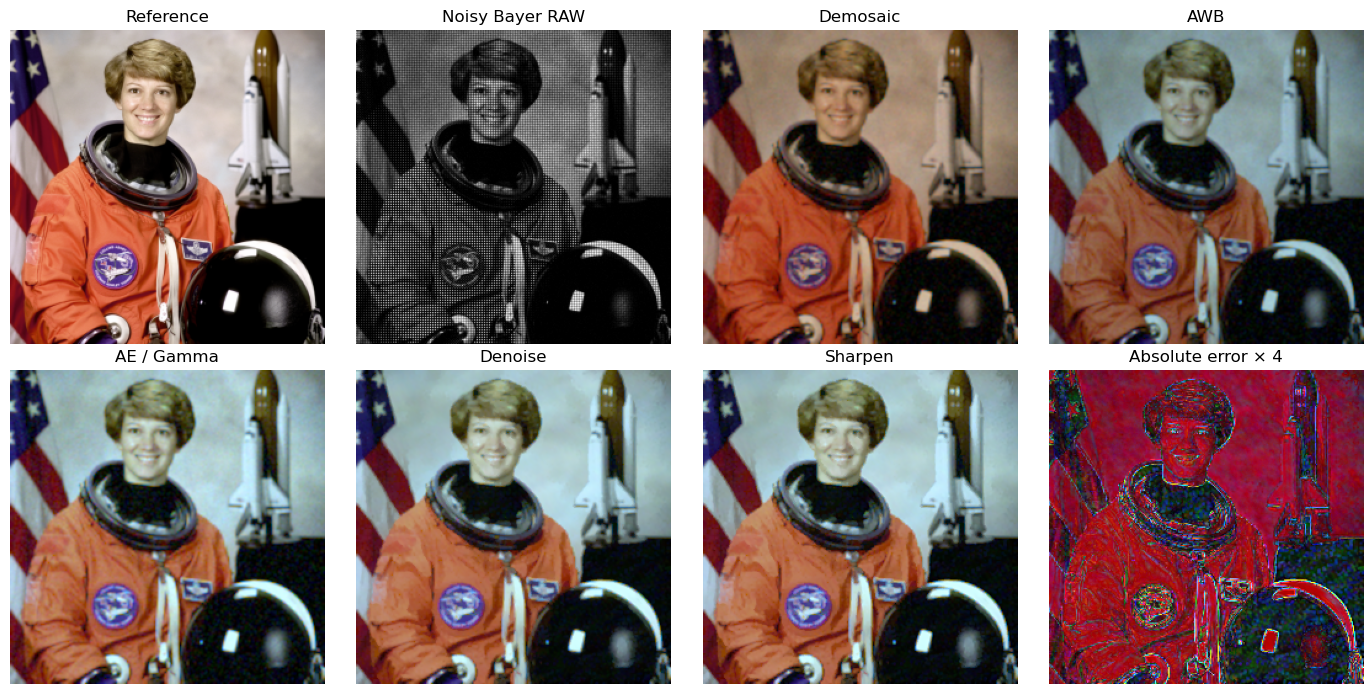

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
images = [
    ("Reference", reference),
    ("Noisy Bayer RAW", noisy_raw),
    ("Demosaic", stages["Demosaic"]),
    ("AWB", stages["+ AWB"]),
    ("AE / Gamma", stages["+ AE / Gamma"]),
    ("Denoise", stages["+ Denoise"]),
    ("Sharpen", stages["+ Sharpen"]),
    ("Absolute error × 4", np.clip(np.abs(reference - sharpened) * 4, 0, 1)),
]
for ax, (title, image) in zip(axes.flat, images):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "isp_pipeline.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. 客观指标

In [5]:
rows = []
for name, image in stages.items():
    rows.append({"Stage": name, **evaluate(reference, image)})

for row in rows:
    print(
        f'{row["Stage"]:>12} | PSNR {row["PSNR (dB)"]:.2f} dB | '
        f'SSIM {row["SSIM"]:.4f} | ΔE00 {row["Mean ΔE00"]:.2f}'
    )

with (OUTPUT / "isp_metrics.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

plt.imsave(OUTPUT / "isp_final.png", sharpened)

    Demosaic | PSNR 15.97 dB | SSIM 0.7319 | ΔE00 12.53
       + AWB | PSNR 15.88 dB | SSIM 0.7414 | ΔE00 15.33
+ AE / Gamma | PSNR 21.33 dB | SSIM 0.7678 | ΔE00 12.23
   + Denoise | PSNR 21.51 dB | SSIM 0.7844 | ΔE00 11.63
   + Sharpen | PSNR 21.52 dB | SSIM 0.7850 | ΔE00 11.73


## 结论

- Demosaic 恢复 RGB 三通道；
- Gray-world AWB 与分位数 AE 修正偏色和曝光；
- 双边滤波抑制噪声，Unsharp Mask 恢复局部清晰度；
- PSNR / SSIM / ΔE00 同时衡量保真度、结构相似性和颜色误差。

本实验是可解释的传统 ISP 教学实现，不等同于厂商量产 Pipeline。